# C02f2 — Systematic lexical control with local likelihood
This replaces chat-generated proposals and chat validation with an explicit search algorithm:
**WordNet synonym sets → inflected local substitutions → exact vocabulary-count changes → word-use statistics → frozen GPT-2 local likelihood → deterministic acceptance.** No chat API or model-generated judgments are used.

Use the same eight original AI texts and exact human reference intervals from your completed C02f run. C02f and C02e2 outputs remain read-only. New outputs go to `results/causal/C02f2_systematic_lexical_control`.

Run top to bottom. GPT-2 is a 124M-parameter numerical scorer, loaded locally in FP32; this fits the 8 GB GPU. CPU execution also works but is slower. The first run may download GPT-2, WordNet and word-frequency resources. Dependencies are checked in the first code cell.

The fixed budget remains min(20, floor(0.05 W)) changed word positions. Full target attainment is reported separately from partial movement and arithmetic feasibility. Model likelihood and dictionary synonymy do not guarantee meaning preservation: inspect the saved edit ledger and side-by-side texts.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
from functools import lru_cache
import json, hashlib, math, re, pickle, sqlite3, importlib.util
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path('..')
BASE = ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR = ROOT/'results/causal/C02e2_raid_feature_guided'
PREVIOUS = ROOT/'results/causal/C02f_controlled_unique_word_share'
OUT = ROOT/'results/causal/C02f2_systematic_lexical_control'
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = dict(version='C02f2_v1', model='openai-community/gpt2', left_tokens=64, right_tokens=16,
    max_candidate_bundles=48, max_pair_bundles=12, max_synonyms_per_position=16,
    batch_size=8, max_local_nll_increase=0.10, max_word_nll_increase=2.0,
    max_sentence_nll_increase=0.10, max_zipf_drop=1.5, min_replacement_zipf=2.5,
    frequency_weight=0.05, seed=42)
# The numerical tolerances are fixed exploratory choices, not validated semantic thresholds.
required={'spacy':'spacy','textstat':'textstat','nltk':'nltk','lemminflect':'lemminflect',
          'wordfreq':'wordfreq','torch':'torch','transformers':'transformers','pyarrow':'pyarrow'}
missing=[p for m,p in required.items() if importlib.util.find_spec(m) is None]
if missing:
    print('%pip install ' + ' '.join(missing))
    raise RuntimeError('Install missing packages in this notebook kernel, restart and rerun.')

def digest(v): return hashlib.sha256(json.dumps(v,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def write_json(path,v):
    tmp=path.with_suffix(path.suffix+'.tmp'); tmp.write_text(json.dumps(v,indent=2,ensure_ascii=False)); tmp.replace(path)

IMPLEMENTATION_HASH = '16eb7a7ebe55667662235136b6395467b55bf122e5fbf0c9c1826b6001cbd2d1'


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Frozen inputs, dictionary, tokenizer, and scorer
The extractor below is copied from C02e2. Local likelihood uses GPT-2 rather than the primary Qwen utility scorer. This still introduces likelihood-based selection; later U(k) changes must be interpreted with that fact in view.


In [2]:
C02D2_OUT = BASE
import importlib.util
required = {
    "spacy": "spacy",
    "textstat": "textstat",
    "pyarrow": "pyarrow",
    "requests": "requests",
}
missing = [
    pip_name
    for module, pip_name in required.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    print("Run this once in the current kernel, restart, and rerun:")
    print("%pip install " + " ".join(sorted(set(missing))))
    raise RuntimeError("Missing packages: " + ", ".join(missing))

import requests
import spacy
import textstat

try:
    nlp = spacy.load("en_core_web_sm")
except OSError as exc:
    print("Run once, restart the kernel, and rerun:")
    print("!python -m spacy download en_core_web_sm")
    raise exc

PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"),
    ("quote", '"'), ("lparen", "("), ("rparen", ")"),
    ("lbracket", "["), ("rbracket", "]"), ("newline", "\n"),
]

GOOGLE_WORDS_PATH = C02D2_OUT / "google-10000-english.txt"
GOOGLE_WORDS_URL = (
    "https://raw.githubusercontent.com/first20hours/"
    "google-10000-english/master/google-10000-english.txt"
)
if not GOOGLE_WORDS_PATH.exists():
    response = requests.get(GOOGLE_WORDS_URL, timeout=60)
    response.raise_for_status()
    GOOGLE_WORDS_PATH.write_bytes(response.content)

google_words = [
    line.strip().lower()
    for line in GOOGLE_WORDS_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
GOOGLE_TOP = {
    100: set(google_words[:100]),
    1000: set(google_words[:1000]),
    10000: set(google_words[:10000]),
}
print("dependencies ready")


dependencies ready


In [3]:
def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector


toy = "One short sentence. Another sentence repeats one short phrase, and one short phrase returns."
toy_vector = extract_fz118(toy)
assert toy_vector.shape == (118,)
print("FZ-118 extractor smoke test passed")


FZ-118 extractor smoke test passed


In [4]:
import nltk, torch
from nltk.corpus import wordnet as wn
from lemminflect import getInflection
from wordfreq import zipf_frequency
from transformers import AutoTokenizer, AutoModelForCausalLM
try: wn.ensure_loaded()
except LookupError:
    nltk.download('wordnet',raise_on_error=True)
    wn.ensure_loaded()
try:
    contract_old=json.loads((PREVIOUS/'frozen_contract.json').read_text())
except FileNotFoundError:
    raise FileNotFoundError('This follow-up needs the frozen_contract.json produced by your C02f run. It does not recompute targets.')
frozen_cases=contract_old['cases']
assert len(frozen_cases)==8 and len({c['source_id'] for c in frozen_cases})==8
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
humans=features.loc[(features.dataset=='raid') & (features.split=='train') & (features.label==0)].copy()
feature_contract=json.loads((BASE/'fz118_feature_contract.json').read_text())
FEATURE_NAMES=feature_contract['feature_names']

def normalize(text): return str(text).translate(str.maketrans({'\n':' ','\r':' '}))
def counts(text):
    w=[t.text.lower() for t in nlp(text) if t.is_alpha]
    return len(set(w)),len(w)
def distance(r,low,high): return max(low-r,0.0,r-high)

for c in frozen_cases:
    v,w=counts(c['original'])
    assert (v,w)==(c['V'],c['W'])
    cached=features.loc[features.source_id==c['source_id']].iloc[0]
    assert np.allclose(extract_fz118(normalize(c['original'])),cached[FEATURE_NAMES].to_numpy(float),atol=1e-9,rtol=0)

torch.manual_seed(CONFIG['seed'])
device='cuda' if torch.cuda.is_available() else 'cpu'
if device=='cuda':
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
# Resume with the exact model revision recorded by the first run.
freeze_path=OUT/'algorithm_contract.json'
previous_contract=json.loads(freeze_path.read_text()) if freeze_path.exists() else None
revision=previous_contract['model_revision'] if previous_contract else 'main'
tokenizer=AutoTokenizer.from_pretrained(CONFIG['model'],revision=revision,use_fast=True)
model=AutoModelForCausalLM.from_pretrained(CONFIG['model'],revision=revision,torch_dtype=torch.float32).to(device).eval()
assert tokenizer.is_fast and tokenizer.eos_token_id is not None
model_revision=getattr(model.config,'_commit_hash',None)
if not model_revision: raise RuntimeError('Could not resolve model revision for reproducibility.')
contract=dict(config=CONFIG,previous_contract_hash=digest(contract_old),implementation=IMPLEMENTATION_HASH,
    model_revision=model_revision,tokenizer_hash=hashlib.sha256(tokenizer.backend_tokenizer.to_str().encode()).hexdigest(),
    versions={p:metadata.version(p) for p in required.values()},wordnet_version=wn.get_version(),spacy_meta=nlp.meta,device=device)
CONTRACT_HASH=digest(contract)
if previous_contract: assert digest(previous_contract)==CONTRACT_HASH, 'Algorithm/resources changed: use a new OUT directory.'
else: write_json(freeze_path,contract)
print('Scorer:',CONFIG['model'],'revision:',model_revision,'device:',device)
display(pd.DataFrame(frozen_cases).drop(columns=['original','source_id']))


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 7627.51it/s]


Scorer: openai-community/gpt2 revision: 607a30d783dfa663caf39e06633721c8d4cfcd7e device: cuda


,case_id,domain,V,W,ratio,low,high,direction,needed_edits,budget,reference_fallback,reference_n
0,raid_micro_01,recipes,129,249,0.518072,0.481328,0.541385,none,0,12,False,30
1,raid_micro_02,wiki,149,245,0.608163,0.519750,0.602648,decrease,2,12,False,30
2,raid_micro_03,reddit,79,107,0.738318,0.595468,0.670929,decrease,8,5,False,30
3,raid_micro_04,news,189,343,0.551020,0.528947,0.564485,none,0,17,False,30
4,raid_micro_05,reddit,93,158,0.588608,0.592174,0.642142,increase,1,7,False,30
5,raid_micro_06,books,137,270,0.507407,0.541293,0.596068,increase,10,13,False,30
6,raid_micro_07,poetry,172,238,0.722689,0.537912,0.625590,decrease,24,11,False,30
7,raid_micro_08,abstracts,63,111,0.567568,0.615342,0.666667,increase,6,5,False,30


## 2. Candidate construction and exact statistics
For one-word replacement (a	o b),
[
Delta V=mathbf1[f(b)=0]-mathbf1[f(a)=1],qquad Delta W=0.
]
For a decrease we also enumerate two singleton types that share a WordNet synonym and replace both with that **same absent surface form**. This reduces V by one at a cost of two edited positions. Both positions must be locally plausible. These bundles remove the requirement that a usable common term already occur in the passage.

The dictionary supplies candidates; it does not disambiguate senses perfectly. Shared synsets are saved. Proper nouns, named entities, stopwords, and nonalphabetic tokens are protected. Inflections are generated for the original Penn tag. POS and inflectional tag must be preserved after re-parsing. Punctuation, whitespace, word count and all unedited token strings stay fixed. No position is edited twice.

Before scoring, bounded candidate batches are chosen by vocabulary progress per edit, rarity penalty, and dictionary-context overlap, with deterministic tie-breaking. This is bounded greedy search, not exhaustive global optimization. A zero-result status includes the actual bottleneck.


In [5]:
POS_MAP={'NOUN':wn.NOUN,'VERB':wn.VERB,'ADJ':wn.ADJ,'ADV':wn.ADV}

def eligible(t,used):
    return t.i not in used and t.is_alpha and not t.is_stop and not t.ent_type_ and t.pos_ in POS_MAP and not t.tag_.startswith('NNP')

def case_form(word,source):
    return word.upper() if source.isupper() else word.capitalize() if source.istitle() else word.lower()

@lru_cache(maxsize=20000)
def lexical_options(lemma,pos,tag):
    options=defaultdict(set)
    for syn in wn.synsets(lemma,pos=POS_MAP[pos]):
        for term in syn.lemmas():
            name=term.name()
            if not name.isalpha(): continue  # one-word operators only
            forms=getInflection(name,tag=tag,inflect_oov=False) or ()
            for form in forms:
                if form.isalpha(): options[form.lower()].add(syn.name())
    return {k:sorted(v) for k,v in sorted(options.items())}

def apply_bundle(text,edits):
    doc=nlp(text)
    for e in sorted(edits,key=lambda e:e['index'],reverse=True):
        t=doc[e['index']]
        text=text[:t.idx]+e['replacement']+text[t.idx+len(t.text):]
    return text

def structural_check(text,bundle,case,used):
    doc=nlp(text); edits=bundle['edits']; ids=[e['index'] for e in edits]
    if len(set(ids))!=len(ids): return None,'duplicate_position'
    if any(not eligible(doc[i],used) for i in ids): return None,'protected_or_used'
    if any(not e['replacement'].isalpha() or e['replacement'].lower()==doc[e['index']].text.lower() for e in edits): return None,'unchanged_or_not_word'
    changed=apply_bundle(text,edits); newdoc=nlp(changed)
    if len(newdoc)!=len(doc): return None,'tokenization_changed'
    if [(s.start,s.end) for s in doc.sents]!=[(s.start,s.end) for s in newdoc.sents]: return None,'sentence_boundaries_changed'
    for i,(a,b) in enumerate(zip(doc,newdoc)):
        if i in ids:
            if a.pos_!=b.pos_ or a.tag_!=b.tag_ or b.ent_type_ or b.is_stop: return None,'pos_inflection_entity_changed'
        elif a.text!=b.text: return None,'collateral_token_change'
        if a.whitespace_!=b.whitespace_: return None,'whitespace_changed'
    v,w=counts(text); nv,nw=counts(changed)
    if nw!=w: return None,'word_count_changed'
    if distance(nv/nw,case['low'],case['high'])>=distance(v/w,case['low'],case['high'])-1e-12: return None,'no_ratio_progress'
    return changed,'eligible'

def enumerate_bundles(text,case,used,remaining):
    doc=nlp(text); freq=Counter(t.text.lower() for t in doc if t.is_alpha)
    candidates=[]; by_replacement=defaultdict(list); stages=Counter()
    context_lemmas={t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop}
    for t in doc:
        if not eligible(t,used): continue
        if case['direction']=='decrease' and freq[t.text.lower()]!=1: continue
        if case['direction']=='increase' and freq[t.text.lower()]<2: continue
        stages['eligible_source_positions']+=1
        options=lexical_options(t.lemma_.lower(),t.pos_,t.tag_)
        options={b:s for b,s in options.items() if b!=t.text.lower()}
        ranked=[]
        for b,synsets in options.items():
            z0=zipf_frequency(t.text.lower(),'en'); z1=zipf_frequency(b,'en')
            if z1<CONFIG['min_replacement_zipf'] or z0-z1>CONFIG['max_zipf_drop']:
                stages['frequency_filtered']+=1; continue
            gloss=set()
            for name in synsets:
                syn=wn.synset(name)
                gloss.update(re.findall(r'[a-z]+',syn.definition().lower()+' '+' '.join(syn.examples()).lower()))
            overlap=len(gloss & context_lemmas)
            edit=dict(index=t.i,old=t.text,replacement=case_form(b,t.text),synsets=synsets,
                      source_count=freq[t.text.lower()],replacement_count=freq[b],zipf_before=z0,zipf_after=z1,gloss_overlap=overlap)
            ranked.append(edit)
        ranked.sort(key=lambda e:(-e['gloss_overlap'],-e['zipf_after'],e['replacement']))
        stages['lexical_options_before_cap']+=len(ranked)
        for e in ranked[:CONFIG['max_synonyms_per_position']]:
            stages['lexical_options_retained']+=1
            b=e['replacement'].lower()
            direct=(case['direction']=='decrease' and freq[b]>0) or (case['direction']=='increase' and freq[b]==0)
            if direct: candidates.append(dict(kind='single',edits=[e]))
            elif case['direction']=='decrease' and freq[b]==0:
                by_replacement[b].append(e)
    pair_candidates=[]
    if case['direction']=='decrease' and remaining>=2:
        for b,items in sorted(by_replacement.items()):
            for a,c in combinations(items,2):
                if a['index']==c['index'] or a['old'].lower()==c['old'].lower(): continue
                if not set(a['synsets']) & set(c['synsets']): continue
                pair_candidates.append(dict(kind='merge_two_types',edits=[a,c]))
    def prior_key(bundle):
        penalty=sum(max(0,e['zipf_before']-e['zipf_after']) for e in bundle['edits'])/len(bundle['edits'])
        overlap=sum(e['gloss_overlap'] for e in bundle['edits'])
        return (len(bundle['edits']),penalty,-overlap,tuple((e['index'],e['replacement']) for e in bundle['edits']))
    pair_candidates.sort(key=prior_key)
    stages['pair_bundles_before_cap']=len(pair_candidates)
    candidates+=pair_candidates[:CONFIG['max_pair_bundles']]
    unique={digest(c):c for c in candidates if len(c['edits'])<=remaining}
    passed=[]
    for key,bundle in sorted(unique.items()):
        changed,reason=structural_check(text,bundle,case,used)
        stages[reason]+=1
        if changed is not None:
            bundle['candidate_id']=key
            passed.append(bundle)
    passed.sort(key=prior_key)
    stages['structural_candidates_before_scoring_cap']=len(passed)
    retained=passed[:CONFIG['max_candidate_bundles']]
    stages['scored_candidates']=len(retained)
    return retained,dict(stages)


## 3. Local likelihood, with both left and right context
For each edited position, score the substituted word **and the following 16 spaCy tokens**, conditional on up to 64 preceding tokens. The unchanged following text tests how the replacement fits its continuation.

Record standard scorer-token perplexity, but rank with total NLL divided by the same alphabetic-word count in the scored span. This avoids rewarding a substitute simply for splitting into more BPE tokens. Source-word surprisal, replacement-word surprisal, span NLL and BPE counts are all logged.

A bundle passes only if every edited position satisfies:
- local NLL increase ≤ 0.10 nats per alphabetic word;
- substituted-word NLL increase ≤ 2.0 nats;
- each affected sentence, scored with preceding context, remains within 0.10 nats per word of that **original sentence**.

The last condition limits cumulative drift across several accepted edits. Perplexity is a fluency/compatibility measurement, not a semantic-equivalence test. All thresholds are exploratory and frozen before outcomes.


In [6]:
score_db=sqlite3.connect(OUT/'likelihood_cache.sqlite3')
score_db.execute('CREATE TABLE IF NOT EXISTS scores (key TEXT PRIMARY KEY, value TEXT NOT NULL)')

def window_request(text,index,word_only=False,sentence=False):
    doc=nlp(text); t=doc[index]
    start=t.sent.start if sentence else index
    end=t.sent.end if sentence else index+1 if word_only else min(len(doc),index+1+CONFIG['right_tokens'])
    left=max(0,start-CONFIG['left_tokens'])
    char_left=doc[left].idx; boundary=doc[start].idx-char_left
    char_end=doc[end-1].idx+len(doc[end-1].text)
    string=text[char_left:char_end]
    words=sum(z.is_alpha for z in doc[start:end])
    assert words>0
    return dict(text=string,boundary=boundary,words=words)

def score_requests(requests):
    keys=[digest(dict(contract=CONTRACT_HASH,request=r)) for r in requests]
    values={}; pending={}
    for key,r in zip(keys,requests):
        hit=score_db.execute('SELECT value FROM scores WHERE key=?',(key,)).fetchone()
        if hit: values[key]=json.loads(hit[0])
        else: pending[key]=r
    items=list(pending.items())
    for begin in range(0,len(items),CONFIG['batch_size']):
        chunk=items[begin:begin+CONFIG['batch_size']]
        encoded=[]
        for key,r in chunk:
            enc=tokenizer(r['text'],add_special_tokens=False,return_offsets_mapping=True)
            ids=[tokenizer.eos_token_id]+enc['input_ids']
            if len(ids)>model.config.n_positions:
                raise RuntimeError('A fixed local window exceeds model context; do not silently truncate it.')
            # EOS is only a shared BOS context. Offsets select scored tokens, not prefix context.
            selected=[j for j,(_,end) in enumerate(enc['offset_mapping']) if end>r['boundary']]
            assert selected
            encoded.append((ids,selected,r['words']))
        width=max(len(e[0]) for e in encoded)
        ids=torch.full((len(chunk),width),tokenizer.eos_token_id,dtype=torch.long,device=device)
        mask=torch.zeros_like(ids)
        for i,(tokens,_,_) in enumerate(encoded):
            ids[i,:len(tokens)]=torch.tensor(tokens,device=device);mask[i,:len(tokens)]=1
        with torch.inference_mode():
            logits=model(input_ids=ids,attention_mask=mask).logits[:,:-1,:].float()
            losses=torch.nn.functional.cross_entropy(logits.transpose(1,2),ids[:,1:],reduction='none')
        for i,((key,_),(tokens,selected,words)) in enumerate(zip(chunk,encoded)):
            total=float(losses[i,selected].sum().item()); n=len(selected)
            value=dict(total_nll=total,n_bpe=n,n_words=words,nll_per_word=total/words,ppl=math.exp(min(700,total/n)))
            values[key]=value
            score_db.execute('INSERT OR REPLACE INTO scores VALUES (?,?)',(key,json.dumps(value)))
        score_db.commit()
    return [values[k] for k in keys]

def evaluate_bundle(text,bundle,case):
    changed=apply_bundle(text,bundle['edits'])
    req=[]
    for e in bundle['edits']:
        i=e['index']
        req.extend([window_request(text,i),window_request(changed,i),
                    window_request(text,i,word_only=True),window_request(changed,i,word_only=True),
                    window_request(case['original'],i,sentence=True),window_request(changed,i,sentence=True)])
    scores=score_requests(req); details=[]
    for j,e in enumerate(bundle['edits']):
        b,a,wb,wa,sb,sa=scores[6*j:6*j+6]
        assert b['n_words']==a['n_words']
        details.append(dict(**e,local_nll_before=b['nll_per_word'],local_nll_after=a['nll_per_word'],
            local_nll_delta=a['nll_per_word']-b['nll_per_word'],ppl_before=b['ppl'],ppl_after=a['ppl'],
            bpe_before=b['n_bpe'],bpe_after=a['n_bpe'],source_word_nll=wb['total_nll'],replacement_word_nll=wa['total_nll'],
            word_nll_delta=wa['total_nll']-wb['total_nll'],sentence_nll_delta_from_original=sa['nll_per_word']-sb['nll_per_word']))
    reason='eligible'
    if any(d['word_nll_delta']>CONFIG['max_word_nll_increase'] for d in details): reason='word_likelihood_rejected'
    elif any(d['local_nll_delta']>CONFIG['max_local_nll_increase'] for d in details): reason='local_likelihood_rejected'
    elif any(d['sentence_nll_delta_from_original']>CONFIG['max_sentence_nll_increase'] for d in details): reason='cumulative_sentence_likelihood_rejected'
    rarity_penalty=float(np.mean([max(0,d['zipf_before']-d['zipf_after']) for d in details]))
    local_delta=float(np.mean([d['local_nll_delta'] for d in details]))
    rank_cost=local_delta+CONFIG['frequency_weight']*rarity_penalty
    return dict(candidate_id=bundle['candidate_id'],kind=bundle['kind'],edits=details,status=reason,
                rank_cost=rank_cost,local_nll_delta=local_delta,rarity_penalty=rarity_penalty,text=changed)


## 4. Run the deterministic eight-case search
Enumerate fresh candidates after each accepted bundle. Score all retained candidates; choose by **ratio-distance reduction per changed position**, then local NLL plus rarity cost, then position/word tie-break. Stop when the target is reached, the position budget is exhausted, or no candidate survives. A no-progress step ends immediately; no identical round is repeated.

Model forward passes are cached by the exact text window and frozen contract. Completed case checkpoints are reused. Detector outputs are not loaded until all treatments are frozen.


In [7]:
# Display-only fix: retain the existing scientific contract and cache keys.
from IPython.display import display, HTML
from html import escape
import time

_status_handle = display(HTML("Starting lexical search…"), display_id=True)
_status_clock = 0.0

def show_search_status(message, force=False):
    global _status_clock
    now = time.monotonic()
    if force or now - _status_clock >= 0.5:
        _status_handle.update(HTML("<div style='font-family:monospace;padding:6px'>" + escape(message) + "</div>"))
        _status_clock = now

all_states=[]
for case_number, case in enumerate(frozen_cases, start=1):
    show_search_status(f"Case {case_number}/{len(frozen_cases)} · {case['case_id']}", force=True)
    path=OUT/(case['case_id']+'_state.json')
    if path.exists():
        state=json.loads(path.read_text())
        assert state['contract_hash']==CONTRACT_HASH
        assert state['state_hash']==digest({k:v for k,v in state.items() if k!='state_hash'})
    else:
        state=dict(case_id=case['case_id'],contract_hash=CONTRACT_HASH,text=case['original'],used=[],accepted=[],candidate_audit=[],stages=[],done=False)
    def checkpoint():
        state['state_hash']=digest({k:v for k,v in state.items() if k!='state_hash'});write_json(path,state)
    while not state['done']:
        v,w=counts(state['text']); remaining=case['budget']-len(state['used'])
        if case['direction']=='none': state.update(done=True,status='already_in_range');break
        if distance(v/w,case['low'],case['high'])<=1e-12: state.update(done=True,status='target_hit');break
        if remaining<=0: state.update(done=True,status='budget_exhausted');break
        bundles,stages=enumerate_bundles(state['text'],case,set(state['used']),remaining)
        step=len(state['stages']); state['stages'].append(dict(step=step,**stages))
        if not bundles: state.update(done=True,status='no_structural_candidate');break
        evaluated=[]
        for candidate_number, bundle in enumerate(bundles, start=1):
            show_search_status(f"Case {case_number}/{len(frozen_cases)} · {case['case_id']} · step {step+1} · candidate {candidate_number}/{len(bundles)}", force=candidate_number==1)
            result=evaluate_bundle(state['text'],bundle,case)
            nv,nw=counts(result['text'])
            result['progress_per_edit']=(distance(v/w,case['low'],case['high'])-distance(nv/nw,case['low'],case['high']))/len(result['edits'])
            result['step']=step
            evaluated.append(result)
        valid=[e for e in evaluated if e['status']=='eligible']
        chosen=None
        if valid:
            chosen=min(valid,key=lambda e:(-e['progress_per_edit'],e['rank_cost'],e['candidate_id']))
        for result in evaluated:
            row={k:v for k,v in result.items() if k!='text'}
            row['selected']=chosen is not None and result['candidate_id']==chosen['candidate_id']
            state['candidate_audit'].append(row)
        if chosen is None: state.update(done=True,status='no_likelihood_acceptable_candidate');break
        state['text']=chosen['text']
        state['used'].extend(e['index'] for e in chosen['edits'])
        state['accepted'].append({k:v for k,v in chosen.items() if k!='text'})
        checkpoint()
    checkpoint();all_states.append(state)
show_search_status('Finished: all eight cases processed.', force=True)


## 5. Primary results: raw control and local compatibility
Review partial closure and accepted-edit coverage before considering detector outcomes. The arithmetic lower bound assumes every changed position removes/adds one type; two-position merges are less efficient. Manual preservation columns are left blank and are not overwritten on rerun. Dictionary and perplexity checks are screening tools, not verified factual equivalence.


,case_id,domain,direction,W,V_before,V_after,ratio_before,ratio_after,low,high,distance_before,distance_after,partial_gap_closure,n_edits,n_bundles,budget,minimum_type_changes,full_target_arithmetically_possible,target_hit,status
0,raid_micro_01,recipes,none,249,129,129,0.518072,0.518072,0.481328,0.541385,0.000000,0.000000,NaN,0,0,12,0,True,True,already_in_range
1,raid_micro_02,wiki,decrease,245,149,149,0.608163,0.608163,0.519750,0.602648,0.005515,0.005515,0.000000,0,0,12,2,True,False,no_likelihood_acceptable_candidate
2,raid_micro_03,reddit,decrease,107,79,79,0.738318,0.738318,0.595468,0.670929,0.067389,0.067389,0.000000,0,0,5,8,False,False,no_likelihood_acceptable_candidate
3,raid_micro_04,news,none,343,189,189,0.551020,0.551020,0.528947,0.564485,0.000000,0.000000,NaN,0,0,17,0,True,True,already_in_range
4,raid_micro_05,reddit,increase,158,93,94,0.588608,0.594937,0.592174,0.642142,0.003566,0.000000,1.000000,1,1,7,1,True,True,target_hit
5,raid_micro_06,books,increase,270,137,141,0.507407,0.522222,0.541293,0.596068,0.033886,0.019071,0.437198,4,4,13,10,True,False,no_likelihood_acceptable_candidate
6,raid_micro_07,poetry,decrease,238,172,166,0.722689,0.697479,0.537912,0.625590,0.097099,0.071889,0.259634,6,6,11,24,False,False,no_likelihood_acceptable_candidate
7,raid_micro_08,abstracts,increase,111,63,64,0.567568,0.576577,0.615342,0.666667,0.047774,0.038765,0.188576,1,1,5,6,False,False,no_likelihood_acceptable_candidate


,case_id,old,replacement,source_count,replacement_count,source_word_nll,replacement_word_nll,local_nll_delta,synsets
0,raid_micro_05,cougar,painter,2,0,13.122078,8.569556,-0.460145,[cougar.n.01]
1,raid_micro_06,web,network,2,0,9.834463,7.296835,-0.046861,[network.n.01]
2,raid_micro_06,home,house,2,0,1.523138,1.796645,0.031281,[family.n.01]
3,raid_micro_06,faced,confronted,2,0,3.228318,3.327561,0.014135,"[confront.v.01, confront.v.02, confront.v.03]"
4,raid_micro_06,deceit,deception,2,0,3.018197,4.041626,0.075816,"[deception.n.02, misrepresentation.n.01]"
5,raid_micro_07,springtime,spring,1,2,9.687292,4.632451,-0.450628,[spring.n.01]
6,raid_micro_07,honeyed,sweet,1,2,11.064917,6.596997,-0.350937,[dulcet.s.02]
7,raid_micro_07,sunlight,sun,1,1,7.596690,5.873805,-0.002123,[sunlight.n.01]
8,raid_micro_07,eternally,forever,1,1,8.171721,8.339149,0.046526,[everlastingly.r.01]
9,raid_micro_07,clear,light,1,1,5.068632,4.537771,0.069764,[clean.s.02]


Out of range: 6 edited: 4 full target hits: 1


,case_id,step,eligible_source_positions,lexical_options_before_cap,lexical_options_retained,frequency_filtered,pair_bundles_before_cap,pos_inflection_entity_changed,eligible,sentence_boundaries_changed,structural_candidates_before_scoring_cap,scored_candidates
0,raid_micro_02,0,49,255,216,126,7,5,10,1.0,10,10
1,raid_micro_03,0,39,167,167,99,1,1,4,0.0,4,4
2,raid_micro_05,0,23,77,77,40,0,17,59,0.0,59,48
3,raid_micro_06,0,35,69,69,47,0,3,59,0.0,59,48
4,raid_micro_06,1,33,67,67,43,0,3,57,0.0,57,48
5,raid_micro_06,2,31,55,55,33,0,3,44,0.0,44,44
6,raid_micro_06,3,29,47,47,33,0,3,36,0.0,36,36
7,raid_micro_06,4,27,43,43,29,0,3,32,0.0,32,32
8,raid_micro_07,0,121,400,382,168,14,10,21,0.0,21,21
9,raid_micro_07,1,119,394,376,168,14,10,20,0.0,20,20


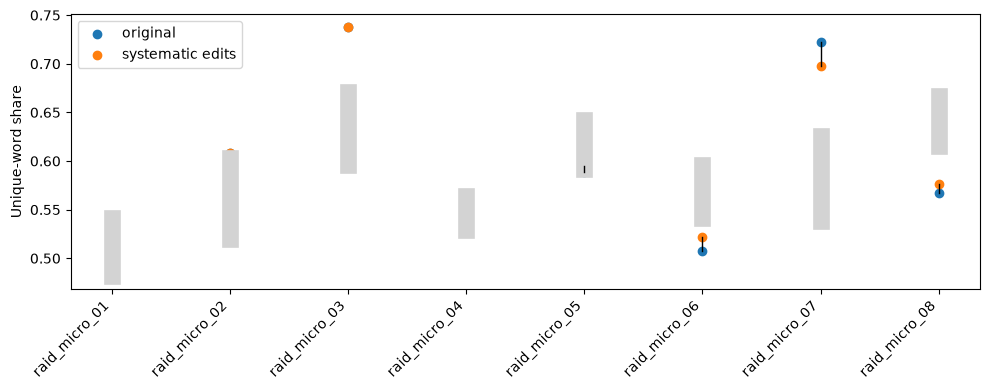

In [8]:
rows=[];edits=[];audit=[];stages=[]
for case,state in zip(frozen_cases,all_states):
    v,w=counts(state['text']); assert w==case['W']
    orig=nlp(case['original']); final=nlp(state['text']); used=set(state['used'])
    assert len(used)==len(state['used'])<=case['budget']
    assert len(orig)==len(final)
    assert all(a.whitespace_==b.whitespace_ and (i in used or a.text==b.text) for i,(a,b) in enumerate(zip(orig,final)))
    d0=distance(case['ratio'],case['low'],case['high']); d1=distance(v/w,case['low'],case['high'])
    rows.append(dict(case_id=case['case_id'],source_id=case['source_id'],domain=case['domain'],direction=case['direction'],
        original=case['original'],treatment=state['text'],W=w,V_before=case['V'],V_after=v,ratio_before=case['ratio'],ratio_after=v/w,
        low=case['low'],high=case['high'],distance_before=d0,distance_after=d1,partial_gap_closure=(d0-d1)/d0 if d0 else np.nan,
        n_edits=len(used),n_bundles=len(state['accepted']),budget=case['budget'],minimum_type_changes=case['needed_edits'],
        full_target_arithmetically_possible=case['needed_edits']<=case['budget'],target_hit=d1<=1e-12,status=state['status']))
    for b in state['accepted']:
        edits.extend(dict(case_id=case['case_id'],step=b['step'],kind=b['kind'],**e) for e in b['edits'])
    for b in state['candidate_audit']:
        audit.extend(dict(case_id=case['case_id'],step=b['step'],candidate_id=b['candidate_id'],kind=b['kind'],status=b['status'],selected=b['selected'],rank_cost=b['rank_cost'],**e) for e in b['edits'])
    stages.extend(dict(case_id=case['case_id'],**s) for s in state['stages'])
results=pd.DataFrame(rows)
treatment_payload=dict(contract_hash=CONTRACT_HASH,treatments=rows)
treatment_freeze_path=OUT/'treatment_freeze.json'
if treatment_freeze_path.exists(): assert digest(json.loads(treatment_freeze_path.read_text()))==digest(treatment_payload)
else: write_json(treatment_freeze_path,treatment_payload)
results.to_csv(OUT/'treatments.csv',index=False)
pd.DataFrame(edits).to_csv(OUT/'accepted_edits.csv',index=False)
pd.DataFrame(audit).to_csv(OUT/'candidate_audit.csv',index=False)
pd.DataFrame(stages).to_csv(OUT/'search_stages.csv',index=False)
review=results[['case_id','original','treatment']].copy();review['meaning_preserved']='';review['notes']=''
if not (OUT/'manual_review.csv').exists():review.to_csv(OUT/'manual_review.csv',index=False)
display(results.drop(columns=['original','treatment','source_id']))
if edits: display(pd.DataFrame(edits)[['case_id','old','replacement','source_count','replacement_count','source_word_nll','replacement_word_nll','local_nll_delta','synsets']])
needs=results.direction.ne('none')
print('Out of range:',int(needs.sum()),'edited:',int((needs & results.n_edits.gt(0)).sum()),'full target hits:',int((needs & results.target_hit).sum()))
if stages:display(pd.DataFrame(stages).fillna(0))
fig,ax=plt.subplots(figsize=(10,4))
for i,r in results.iterrows():
    ax.plot([i,i],[r.low,r.high],color='lightgray',linewidth=12)
    ax.plot([i,i],[r.ratio_before,r.ratio_after],color='black',linewidth=1)
ax.scatter(range(len(results)),results.ratio_before,label='original')
ax.scatter(range(len(results)),results.ratio_after,label='systematic edits')
ax.set_xticks(range(len(results)),results.case_id,rotation=45,ha='right');ax.set_ylabel('Unique-word share');ax.legend();fig.tight_layout()
fig.savefig(OUT/'raw_ratio_movement.png',dpi=180);plt.show()


## 6. Secondary detector and feature-contribution outcomes
Only now load the frozen C02e2 detector. Report raw feature, its tree-path contribution, all other contributions, and overall probability separately. The global contribution of unique-word share is not a universal monotonic function of its raw value. Other feature changes remain collateral outcomes.


In [9]:
assert digest(json.loads(treatment_freeze_path.read_text())) == digest(treatment_payload)
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f: detector=pickle.load(f)
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
before=pd.DataFrame([extract_fz118(normalize(t)) for t in results.original],columns=FEATURE_NAMES)
after=pd.DataFrame([extract_fz118(normalize(t)) for t in results.treatment],columns=FEATURE_NAMES)
assert np.allclose(before.share_unique_words,results.ratio_before)
assert np.allclose(after.share_unique_words,results.ratio_after)
p0=detector.predict_proba(before[model_features])[:,1]
p1=detector.predict_proba(after[model_features])[:,1]
outcomes=results.drop(columns=['original','treatment']).copy()
outcomes['score_before']=p0; outcomes['score_after']=p1; outcomes['score_change']=p1-p0
ops=pd.read_csv(PRIOR/'raid_operating_points_p95_p99.csv')
for op in ops.itertuples():
    threshold=op.validation_human_threshold; name=f'p{round(op.human_specificity_target*100)}'
    outcomes[name+'_crossed_below']=(p0>=threshold)&(p1<threshold)
    outcomes[name+'_crossed_above']=(p0<threshold)&(p1>=threshold)
outcomes.to_csv(OUT/'secondary_detector_outcomes.csv',index=False)
collateral=[]
scale=humans[FEATURE_NAMES].quantile(.75)-humans[FEATURE_NAMES].quantile(.25)
for i,case_id in enumerate(results.case_id):
    for feature in FEATURE_NAMES:
        delta=float(after.iloc[i][feature]-before.iloc[i][feature])
        collateral.append(dict(case_id=case_id,feature=feature,before=float(before.iloc[i][feature]),after=float(after.iloc[i][feature]),
            delta=delta,delta_human_iqr=delta/scale[feature] if scale[feature]>0 else np.nan))
pd.DataFrame(collateral).to_csv(OUT/'raw_feature_collateral.csv',index=False)
display(outcomes[['case_id','direction','n_edits','target_hit','ratio_before','ratio_after','score_change','p95_crossed_below','p99_crossed_below']])
print('Evaluate raw manipulation success separately from score movement; inspect manual_review.csv before calling the edits meaning-preserving.')


# Exact tree-path contributions: descriptive attribution, not a causal feature effect.
def forest_contributions(model, frame):
    X = frame[model_features].to_numpy(dtype=np.float32)
    assert list(model.classes_) == [0, 1]
    c = np.zeros_like(X, dtype=float)
    bias = 0.0
    for estimator in model.estimators_:
        tree = estimator.tree_
        values = tree.value[:, 0, :]
        prob = values[:, 1] / values.sum(axis=1)
        bias += prob[0]
        for row in range(len(X)):
            node = 0
            while tree.feature[node] >= 0:
                feature = tree.feature[node]
                child = tree.children_left[node] if X[row, feature] <= tree.threshold[node] else tree.children_right[node]
                c[row, feature] += prob[child] - prob[node]
                node = child
    c /= len(model.estimators_); bias /= len(model.estimators_)
    assert np.allclose(bias + c.sum(axis=1), model.predict_proba(frame[model_features])[:, 1], atol=1e-9)
    return c
cb = forest_contributions(detector, before)
ca = forest_contributions(detector, after)
j = model_features.index('share_unique_words')
outcomes['unique_word_contribution_before'] = cb[:, j]
outcomes['unique_word_contribution_after'] = ca[:, j]
outcomes['unique_word_contribution_change'] = ca[:, j] - cb[:, j]
outcomes['other_contribution_change'] = (ca-cb).sum(axis=1) - (ca[:, j]-cb[:, j])
outcomes.to_csv(OUT/'secondary_detector_outcomes.csv',index=False)
display(outcomes[['case_id','ratio_before','ratio_after','unique_word_contribution_change','other_contribution_change','score_change']])


,case_id,direction,n_edits,target_hit,ratio_before,ratio_after,score_change,p95_crossed_below,p99_crossed_below
0,raid_micro_01,none,0,True,0.518072,0.518072,0.000000e+00,False,False
1,raid_micro_02,decrease,0,False,0.608163,0.608163,-2.220446e-16,False,False
2,raid_micro_03,decrease,0,False,0.738318,0.738318,1.110223e-16,False,False
3,raid_micro_04,none,0,True,0.551020,0.551020,0.000000e+00,False,False
4,raid_micro_05,increase,1,True,0.588608,0.594937,1.587302e-04,False,False
5,raid_micro_06,increase,4,False,0.507407,0.522222,-1.296219e-02,True,False
6,raid_micro_07,decrease,6,False,0.722689,0.697479,-2.928776e-02,True,False
7,raid_micro_08,increase,1,False,0.567568,0.576577,-3.416667e-03,False,False


Evaluate raw manipulation success separately from score movement; inspect manual_review.csv before calling the edits meaning-preserving.


,case_id,ratio_before,ratio_after,unique_word_contribution_change,other_contribution_change,score_change
0,raid_micro_01,0.518072,0.518072,0.000000,0.000000,0.000000e+00
1,raid_micro_02,0.608163,0.608163,0.000000,0.000000,-2.220446e-16
2,raid_micro_03,0.738318,0.738318,0.000000,0.000000,1.110223e-16
3,raid_micro_04,0.551020,0.551020,0.000000,0.000000,0.000000e+00
4,raid_micro_05,0.588608,0.594937,-0.001142,0.001301,1.587302e-04
5,raid_micro_06,0.507407,0.522222,-0.008409,-0.004553,-1.296219e-02
6,raid_micro_07,0.722689,0.697479,-0.010496,-0.018792,-2.928776e-02
7,raid_micro_08,0.567568,0.576577,0.000333,-0.003750,-3.416667e-03


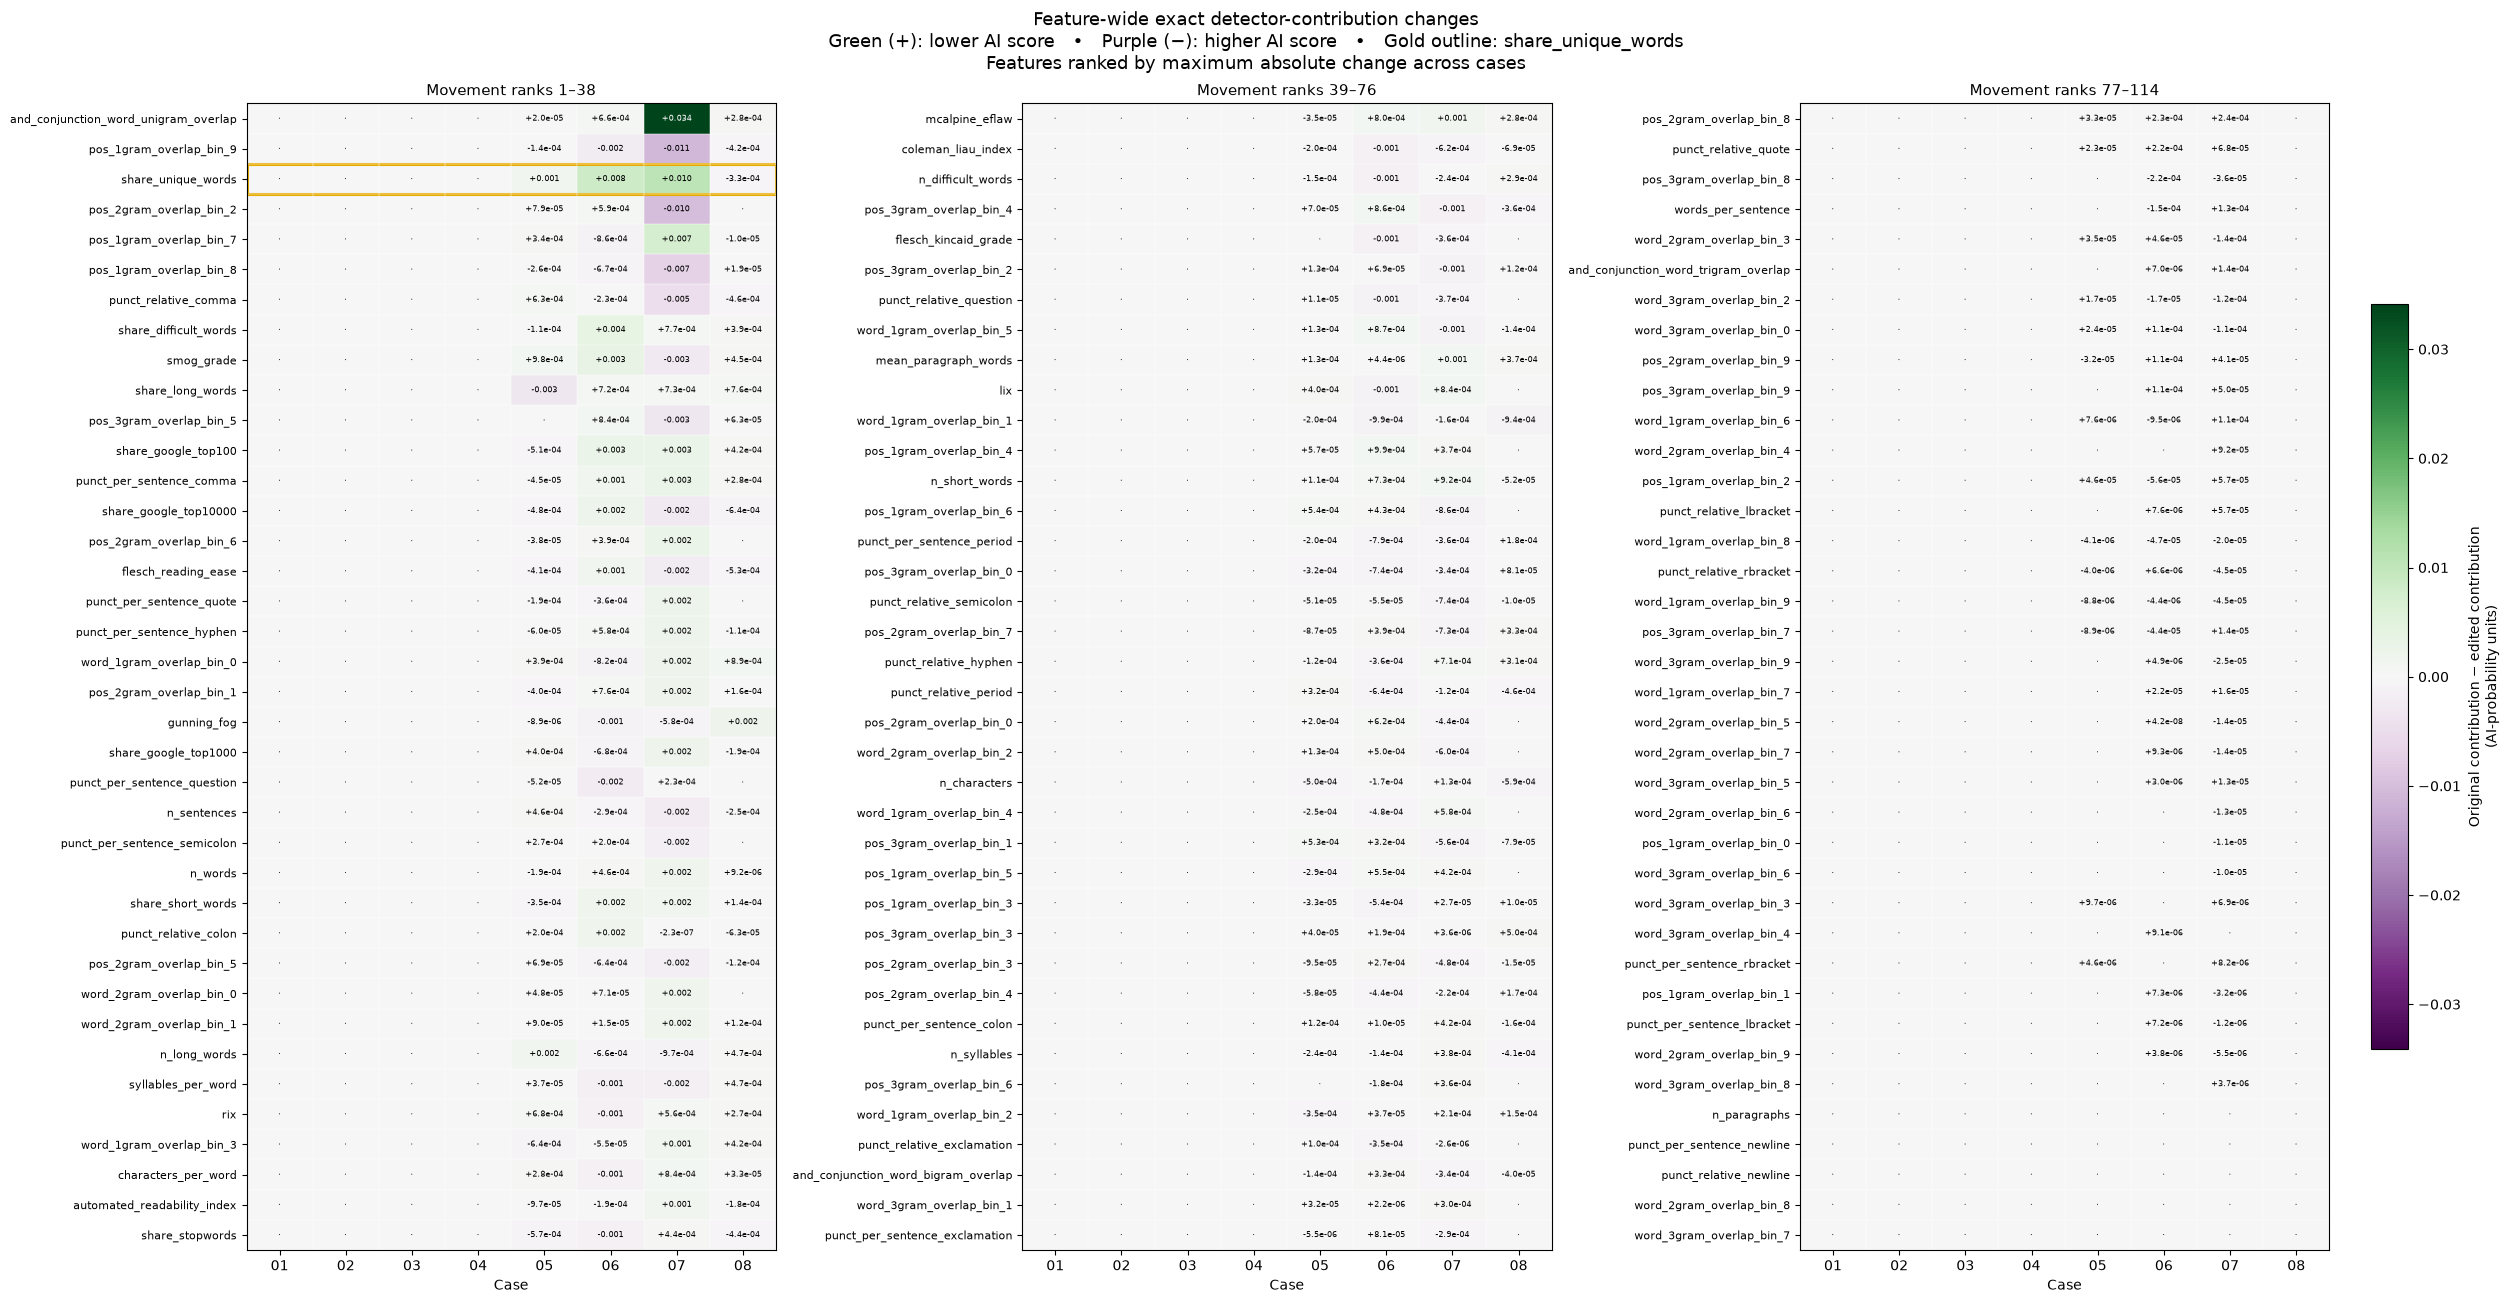

,case_id,unique_word_score_reduction,other_features_score_reduction,total_score_reduction
0,raid_micro_01,0.000000,0.000000,0.000000
1,raid_micro_02,0.000000,0.000000,0.000000
2,raid_micro_03,0.000000,0.000000,0.000000
3,raid_micro_04,0.000000,0.000000,0.000000
4,raid_micro_05,0.001142,-0.001301,-0.000159
5,raid_micro_06,0.008409,0.004553,0.012962
6,raid_micro_07,0.010496,0.018792,0.029288
7,raid_micro_08,-0.000333,0.003750,0.003417


Saved: ../results/causal/C02f2_systematic_lexical_control/feature_wide_contribution_changes.png


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from IPython.display import display

# Exact contribution arrays from the secondary outcome cell:
# cb = original contributions; ca = edited contributions.
required = ["cb", "ca", "results", "model_features", "OUT"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the secondary detector-outcome cell first. Missing: "
        + ", ".join(missing)
    )

before_contrib = np.asarray(cb, dtype=float)
after_contrib = np.asarray(ca, dtype=float)
features_plot = list(model_features)
case_ids = results["case_id"].astype(str).tolist()

expected_shape = (len(case_ids), len(features_plot))
if before_contrib.shape != expected_shape or after_contrib.shape != expected_shape:
    raise ValueError(
        f"Expected contribution arrays of shape {expected_shape}; "
        f"got {before_contrib.shape} and {after_contrib.shape}."
    )

# Positive = contribution to AI probability decreased.
# This is score-direction movement, not distance to a human feature distribution.
score_reduction = before_contrib - after_contrib
score_reduction[np.abs(score_reduction) < 1e-12] = 0.0

movement = pd.DataFrame(
    score_reduction.T,
    index=features_plot,
    columns=case_ids,
)
movement.index.name = "feature"

# Rank by observed movement across cases; retain every feature.
ranking = pd.DataFrame({
    "feature": features_plot,
    "max_absolute_change": np.max(np.abs(score_reduction), axis=0),
    "mean_score_reduction": np.mean(score_reduction, axis=0),
    "n_cases_reduced": np.sum(score_reduction > 0, axis=0),
    "n_cases_increased": np.sum(score_reduction < 0, axis=0),
}).sort_values(
    ["max_absolute_change", "feature"],
    ascending=[False, True],
).reset_index(drop=True)

ordered_features = ranking["feature"].tolist()
movement = movement.loc[ordered_features]

# All panels share one linear color scale.
limit = float(np.max(np.abs(score_reduction)))
limit = limit if limit > 0 else 1e-6
norm = TwoSlopeNorm(vmin=-limit, vcenter=0.0, vmax=limit)

n_panels = 3
rows_per_panel = int(np.ceil(len(ordered_features) / n_panels))

fig, axes = plt.subplots(
    1,
    n_panels,
    figsize=(25, max(10, rows_per_panel * 0.34)),
    layout="constrained",
)

for panel_index, ax in enumerate(axes):
    start = panel_index * rows_per_panel
    subset = ordered_features[start:start + rows_per_panel]

    if not subset:
        ax.axis("off")
        continue

    values = movement.loc[subset].to_numpy()

    im = ax.imshow(
        values,
        aspect="auto",
        cmap="PRGn",
        norm=norm,
        interpolation="nearest",
    )

    ax.set_xticks(
        np.arange(len(case_ids)),
        [case_id.replace("raid_micro_", "") for case_id in case_ids],
    )
    ax.set_yticks(np.arange(len(subset)), subset, fontsize=8)
    ax.set_xlabel("Case")
    ax.set_title(
        f"Movement ranks {start + 1}–{start + len(subset)}",
        fontsize=11,
    )

    # Small grid separates cells without obscuring the colors.
    ax.set_xticks(np.arange(-0.5, len(case_ids), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(subset), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.35)
    ax.tick_params(which="minor", bottom=False, left=False)

    for row_index in range(len(subset)):
        for column_index in range(len(case_ids)):
            value = values[row_index, column_index]

            if value == 0:
                label = "·"
            elif abs(value) < 0.001:
                label = f"{value:+.1e}"
            else:
                label = f"{value:+.3f}"

            ax.text(
                column_index,
                row_index,
                label,
                ha="center",
                va="center",
                fontsize=6,
                color="white" if abs(value) > 0.60 * limit else "black",
            )

    # Highlight the explicitly controlled raw feature.
    if "share_unique_words" in subset:
        row_index = subset.index("share_unique_words")
        ax.add_patch(Rectangle(
            (-0.5, row_index - 0.5),
            len(case_ids),
            1,
            fill=False,
            edgecolor="#e6ab02",
            linewidth=2.2,
        ))

fig.suptitle(
    "Feature-wide exact detector-contribution changes\n"
    "Green (+): lower AI score   •   Purple (−): higher AI score   "
    "•   Gold outline: share_unique_words\n"
    "Features ranked by maximum absolute change across cases",
    fontsize=13,
)

colorbar = fig.colorbar(im, ax=list(axes), shrink=0.65, pad=0.02)
colorbar.set_label(
    "Original contribution − edited contribution\n"
    "(AI-probability units)"
)

OUT.mkdir(parents=True, exist_ok=True)
figure_path = OUT / "feature_wide_contribution_changes.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

movement.to_csv(OUT / "feature_wide_contribution_changes.csv")
ranking.to_csv(OUT / "feature_wide_contribution_ranking.csv", index=False)

# Summing all feature changes reconstructs the overall score reduction.
total_reduction = score_reduction.sum(axis=1)
unique_index = features_plot.index("share_unique_words")
unique_reduction = score_reduction[:, unique_index]

summary = pd.DataFrame({
    "case_id": case_ids,
    "unique_word_score_reduction": unique_reduction,
    "other_features_score_reduction": total_reduction - unique_reduction,
    "total_score_reduction": total_reduction,
})

if (
    "outcomes" in globals()
    and {"case_id", "score_change"}.issubset(outcomes.columns)
):
    reported_change = (
        outcomes.set_index("case_id")
        .loc[case_ids, "score_change"]
        .to_numpy(float)
    )
    np.testing.assert_allclose(
        total_reduction,
        -reported_change,
        atol=1e-9,
        rtol=0,
    )

display(summary)
print("Saved:", figure_path)

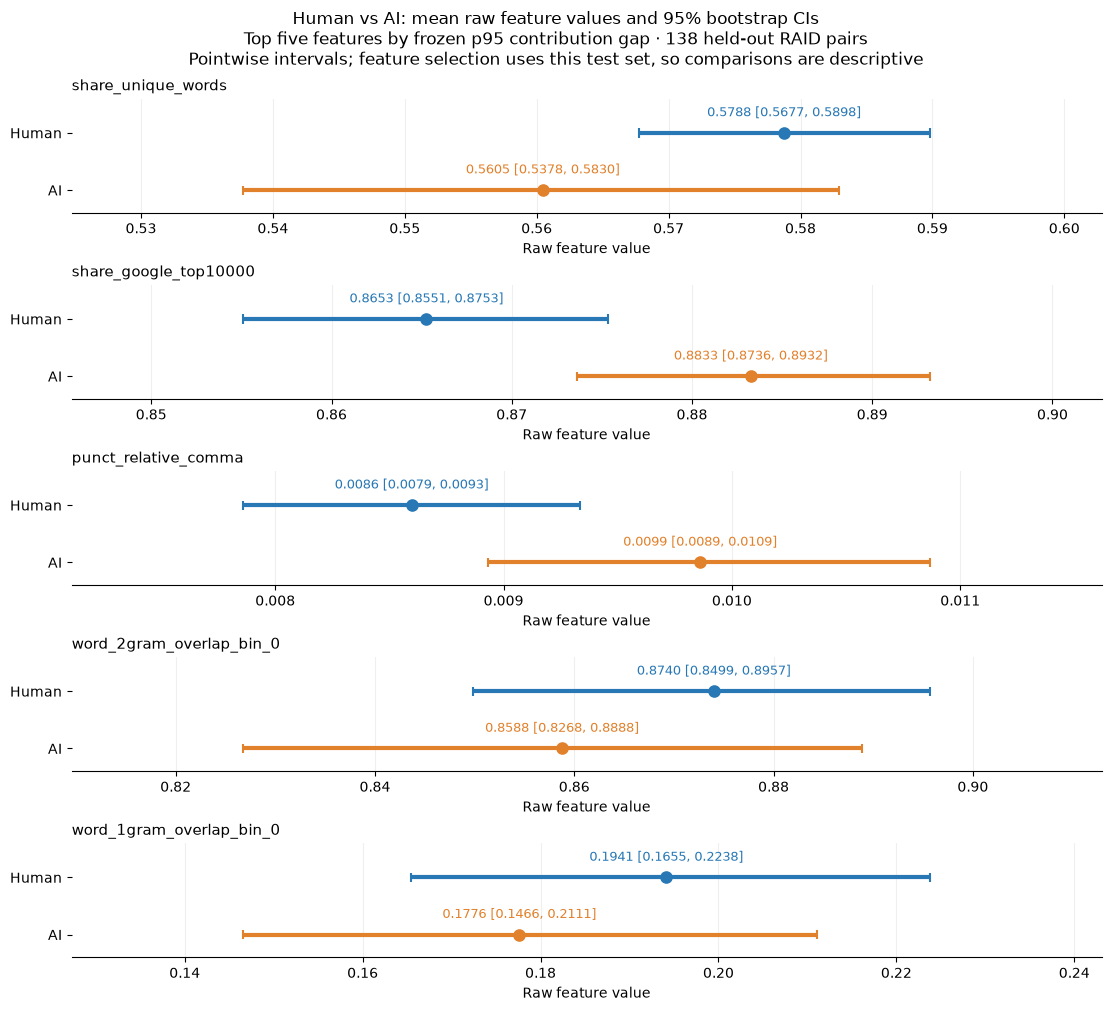

n      mean    ci_low   ci_high
feature                  group                                   
share_unique_words       Human  138  0.578754  0.567731  0.589818
                         AI     138  0.560465  0.537761  0.582956
share_google_top10000    Human  138  0.865269  0.855111  0.875337
                         AI     138  0.883267  0.873604  0.893205
punct_relative_comma     Human  138  0.008598  0.007860  0.009335
                         AI     138  0.009861  0.008931  0.010868
word_2gram_overlap_bin_0 Human  138  0.874004  0.849866  0.895698
                         AI     138  0.858772  0.826791  0.888824
word_1gram_overlap_bin_0 Human  138  0.194141  0.165490  0.223780
                         AI     138  0.177619  0.146592  0.211112

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BOOTSTRAPS = 10_000
SEED = 42

# Frozen C02e2 importance ranking.
ranking = pd.read_csv(
    PRIOR / "raid_exact_contribution_gap_p95_p99.csv"
)
ranking["absolute_p95_gap"] = ranking["p95"].abs()

top5 = (
    ranking.sort_values(
        ["absolute_p95_gap", "feature"],
        ascending=[False, True],
    )
    .head(5)["feature"]
    .tolist()
)

# Raw, original held-out documents—not the eight rewritten cases.
feature_data = pd.read_parquet(BASE / "fz118_paired_features.parquet")
test_data = feature_data.loc[
    feature_data["dataset"].eq("raid")
    & feature_data["split"].eq("test")
    & feature_data["label"].isin([0, 1])
].copy()

required = ["pair_id", "label", *top5]
missing = [column for column in required if column not in test_data]
if missing:
    raise ValueError(f"Missing columns: {missing}")

if test_data["pair_id"].isna().any():
    raise ValueError("Some test documents have no pair_id.")

# Require exactly one human and one AI document per pair.
pair_counts = (
    test_data.groupby(["pair_id", "label"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
)
if not pair_counts.eq(1).all().all():
    raise ValueError(
        "Expected one human and one AI document per test pair. "
        "Inspect pair_counts before bootstrapping."
    )

pair_ids = pair_counts.index
human = (
    test_data.loc[test_data["label"].eq(0)]
    .set_index("pair_id")
    .loc[pair_ids, top5]
    .to_numpy(float)
)
ai = (
    test_data.loc[test_data["label"].eq(1)]
    .set_index("pair_id")
    .loc[pair_ids, top5]
    .to_numpy(float)
)

if not np.isfinite(human).all() or not np.isfinite(ai).all():
    raise ValueError("Non-finite feature values found.")

n_pairs = len(pair_ids)
if n_pairs < 2:
    raise ValueError("At least two matched pairs are required.")

# Resample paired units together, preserving human–AI matching.
rng = np.random.default_rng(SEED)
bootstrap_human = np.empty((BOOTSTRAPS, len(top5)))
bootstrap_ai = np.empty_like(bootstrap_human)

for start in range(0, BOOTSTRAPS, 250):
    stop = min(start + 250, BOOTSTRAPS)
    indices = rng.integers(
        0, n_pairs, size=(stop - start, n_pairs)
    )
    bootstrap_human[start:stop] = human[indices].mean(axis=1)
    bootstrap_ai[start:stop] = ai[indices].mean(axis=1)

rows = []
for group, values, replicates in [
    ("Human", human, bootstrap_human),
    ("AI", ai, bootstrap_ai),
]:
    means = values.mean(axis=0)
    lower, upper = np.quantile(
        replicates, [0.025, 0.975], axis=0
    )
    for j, feature in enumerate(top5):
        rows.append({
            "feature": feature,
            "group": group,
            "n": n_pairs,
            "mean": means[j],
            "ci_low": lower[j],
            "ci_high": upper[j],
        })

summary = pd.DataFrame(rows)

colors = {"Human": "#2878B5", "AI": "#E1812C"}
fig, axes = plt.subplots(
    len(top5), 1,
    figsize=(11, 10),
    layout="constrained",
)

for ax, feature in zip(axes, top5):
    panel = summary.loc[
        summary["feature"].eq(feature)
    ].set_index("group")

    for y, group in [(1, "Human"), (0, "AI")]:
        row = panel.loc[group]
        color = colors[group]

        ax.hlines(
            y, row["ci_low"], row["ci_high"],
            color=color, linewidth=3,
        )
        ax.vlines(
            [row["ci_low"], row["ci_high"]],
            y - 0.08, y + 0.08,
            color=color, linewidth=1.5,
        )
        ax.scatter(
            row["mean"], y,
            color=color, s=65, zorder=3,
        )
        ax.annotate(
            f'{row["mean"]:.4f} '
            f'[{row["ci_low"]:.4f}, {row["ci_high"]:.4f}]',
            (row["mean"], y),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            color=color,
        )

    ax.set_title(feature, loc="left", fontsize=11)
    ax.set_yticks([1, 0], ["Human", "AI"])
    ax.set_ylim(-0.4, 1.6)
    ax.margins(x=0.25)
    ax.set_xlabel("Raw feature value")
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right", "left"]].set_visible(False)

fig.suptitle(
    "Human vs AI: mean raw feature values and 95% bootstrap CIs\n"
    f"Top five features by frozen p95 contribution gap · "
    f"{n_pairs} held-out RAID pairs\n"
    "Pointwise intervals; feature selection uses this test set, "
    "so comparisons are descriptive",
    fontsize=12,
)

plt.show()

display(
    summary.set_index(["feature", "group"])
    .reindex(
        pd.MultiIndex.from_product(
            [top5, ["Human", "AI"]],
            names=["feature", "group"],
        )
    )
)

OUT.mkdir(parents=True, exist_ok=True)
fig.savefig(
    OUT / "top5_human_ai_mean_95ci.png",
    dpi=200,
    bbox_inches="tight",
)
summary.to_csv(
    OUT / "top5_human_ai_mean_95ci.csv",
    index=False,
)

## Interpretation and references
- A positive result establishes that this bounded dictionary-and-likelihood operator moved the measured feature under these constraints; it does not establish distributional equivalence or semantic invariance.
- Rejected edits are informative: `search_stages.csv` separates absent lexical candidates, frequency filtering, structural failures and scorer rejection. `candidate_audit.csv` contains scored candidate details. No chat validator is involved.
- WordNet can miss paraphrases and confound senses; this initial implementation supports one-word edits and two-position lexical merges, not free-form phrase generation.
- Selecting with GPT-2 likelihood can itself alter later probability-based observables. Preserve that distinction in downstream RELIC experiments.

Sources: [lexical candidate generation and contextual ranking](https://aclanthology.org/2022.lrec-1.747/), [WordNet](https://www.nltk.org/howto/wordnet.html), [LemmInflect](https://lemminflect.readthedocs.io/en/latest/inflections/), [perplexity and tokenization](https://huggingface.co/docs/transformers/en/perplexity).
